# TensorForge 2.1.0 — Final model release

**Model:** `tf-phase2-drive-2.1.0`  
**Release:** `v2.1.0`  
**Task:** classify support tickets by primary category, optional secondary category, and urgency.

This report uses the saved evaluation from a deterministic **stratified 75/25 split of `datasets/train.csv`**: 3,000 examples for fitting and 1,000 untouched examples for testing. Scores below come from the model fitted on the 75% fold. After evaluation, a separate final artifact was refit using all 4,000 training rows plus 800 supplied validation rows. The final artifact must not be re-scored on those same training examples as if they were an independent test set.

The data are synthetic workshop examples. Good held-out scores on this distribution do not guarantee quality on real customer messages or the judges' independent data.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
metrics = json.loads((ROOT / "artifacts/evaluation_metrics.json").read_text(encoding="utf-8"))
config = json.loads((ROOT / "configs/training.json").read_text(encoding="utf-8"))
assert metrics["model_version"] == "tf-phase2-drive-2.1.0"
assert metrics["evaluation_split"]["fit_examples"] == 3000
assert metrics["evaluation_split"]["test_examples"] == 1000
print(metrics["model_version"])
print(metrics["evaluation_note"])
display(pd.DataFrame(metrics["evaluation_split"], index=["split"]).T)


tf-phase2-drive-2.1.0
Metrics are from the untouched 25% stratified test fold of train.csv. After scoring, the deployment artifact was refit on train.csv plus validation.csv; do not evaluate that final artifact on these same examples.


,split
method,stratified random split by primary category fr...
test_size,0.25
random_state,42
fit_examples,3000
test_examples,1000
validation_file_used_for_test_scoring,False


## Overall held-out scores

Accuracy is the fraction of correct predictions. Macro-F1 computes F1 per class and averages classes equally, so common labels do not dominate the summary. Secondary labels include a `__none__` outcome. These metrics include the model's documented post-prediction consistency and precedence rules.

,accuracy (%),macro-F1 (%)
prediction target,,
category,99.0,98.92
secondary_category,99.8,98.84
is_urgent,99.9,99.71


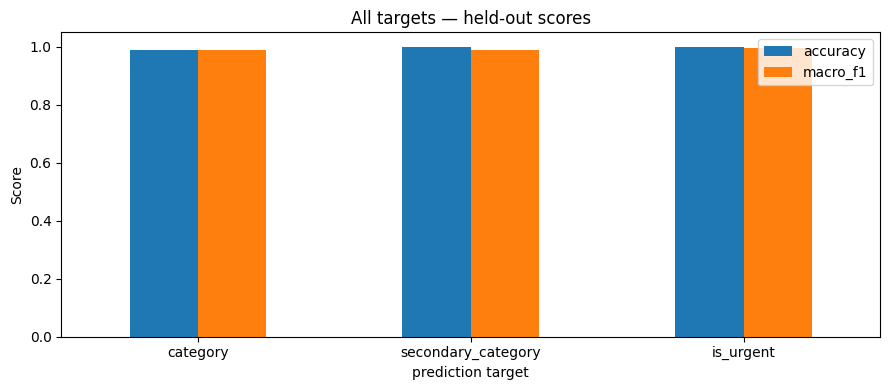

In [2]:
overall = pd.DataFrame(metrics["validation"]).T
overall.index.name = "prediction target"
display((100 * overall).round(2).rename(columns={"accuracy": "accuracy (%)", "macro_f1": "macro-F1 (%)"}))
overall.plot.bar(figsize=(9, 4), ylim=(0, 1.05), rot=0, title="All targets — held-out scores")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


## Models used and why

All targets use a scikit-learn TF-IDF text pipeline combining word 1–2 grams with character n-grams. Word phrases capture issue concepts; character fragments retain signal across misspellings, morphology, Unicode scripts, and Latin-script transliteration. Ticket channel, subject, and message are features; an optional language hint is included when supplied. Ticket IDs are excluded. Text is Unicode NFC-normalized.

- **Primary category — balanced Logistic Regression, `C=100`.** A regularized linear model over sparse word and boundary-aware `char_wb` 2–6-gram features is efficient and returns class probabilities for routing and confidence. Balanced class weights reduce majority-class preference. This configuration was retained from the project comparison experiments and performed strongly on the recorded stratified fold.
- **Secondary category — sigmoid-calibrated Linear SVM, `C=1`, cutoff `0.20`.** A margin-based linear classifier works well with sparse high-dimensional text; sigmoid calibration provides probabilities for the optional-label threshold. Three-fold calibration is used. The lower cutoff reflects that a secondary issue is optional and distinct from the primary.
- **Urgency — balanced Logistic Regression, `C=40`, cutoff `0.30`.** Calibrated class probabilities support an explicit operating threshold, while class balancing helps retain the rarer urgent examples. Urgency is routed after scoring; spam is forced nonurgent.

These are practical, CPU-friendly text models with no external inference service. The parameters and thresholds are fixed in `configs/training.json`; this report does not tune them on the 25% test fold. Fixed category-to-team routing and narrow safety/missing-item/delay precedence rules run after model scores.

In [3]:
config_rows = []
for target, values in config["models"].items():
    config_rows.append({
        "target": target,
        "estimator": values["estimator"],
        "C": values["C"],
        "class_weight": values["class_weight"],
        "normalization": values["normalize"],
        "character analyzer": values["char_analyzer"],
        "character n-grams": str(values["char_ngram_range"]),
        "decision threshold": values.get("threshold", "argmax"),
    })
display(pd.DataFrame(config_rows).set_index("target"))


,estimator,C,class_weight,normalization,character analyzer,character n-grams,decision threshold
target,,,,,,,
category,logistic_regression,100.0,balanced,False,char_wb,"[2, 6]",argmax
secondary_category,calibrated_svm,1.0,None,True,char,"[2, 6]",0.2
is_urgent,logistic_regression,40.0,balanced,True,char,"[2, 5]",0.3


## Every class: precision, recall, F1, and support

The following reports include every evaluated label plus macro and weighted averages. Support is the number of test examples for the class. Sparse secondary labels have low support, so their scores are less certain.

In [4]:
for target, report in metrics["classification_reports"].items():
    rows = {label: scores for label, scores in report.items() if isinstance(scores, dict)}
    table = pd.DataFrame(rows).T
    print("\n", target)
    display(table[["precision", "recall", "f1-score", "support"]].round(4))



 category


,precision,recall,f1-score,support
account_promo,0.9889,0.9889,0.9889,90.0
app_technical,0.9756,1.0000,0.9877,80.0
delivery_delay,0.9740,1.0000,0.9868,150.0
food_quality,1.0000,0.9857,0.9928,70.0
general_inquiry,0.9804,1.0000,0.9901,50.0
lost_item,0.9796,0.9600,0.9697,50.0
order_missing_wrong,1.0000,0.9833,0.9916,120.0
payment_refund,1.0000,0.9944,0.9972,180.0
ride_trip_issue,0.9928,0.9857,0.9892,140.0
safety_conduct,1.0000,0.9750,0.9873,40.0



 secondary_category


,precision,recall,f1-score,support
__none__,1.0000,0.9989,0.9994,903.0
app_technical,1.0000,1.0000,1.0000,16.0
delivery_delay,1.0000,0.9286,0.9630,14.0
order_missing_wrong,1.0000,1.0000,1.0000,8.0
payment_refund,0.9375,1.0000,0.9677,30.0
ride_trip_issue,1.0000,1.0000,1.0000,29.0
macro avg,0.9896,0.9879,0.9884,1000.0
weighted avg,0.9981,0.9980,0.9980,1000.0



 is_urgent


,precision,recall,f1-score,support
false,0.9989,1.0000,0.9994,905.0
true,1.0000,0.9895,0.9947,95.0
macro avg,0.9994,0.9947,0.9971,1000.0
weighted avg,0.9990,0.9990,0.9990,1000.0


## Confusion matrices

Rows are actual labels; columns are predicted labels. Counts are the final predictions from the held-out fold, after the category precedence and consistency rules.

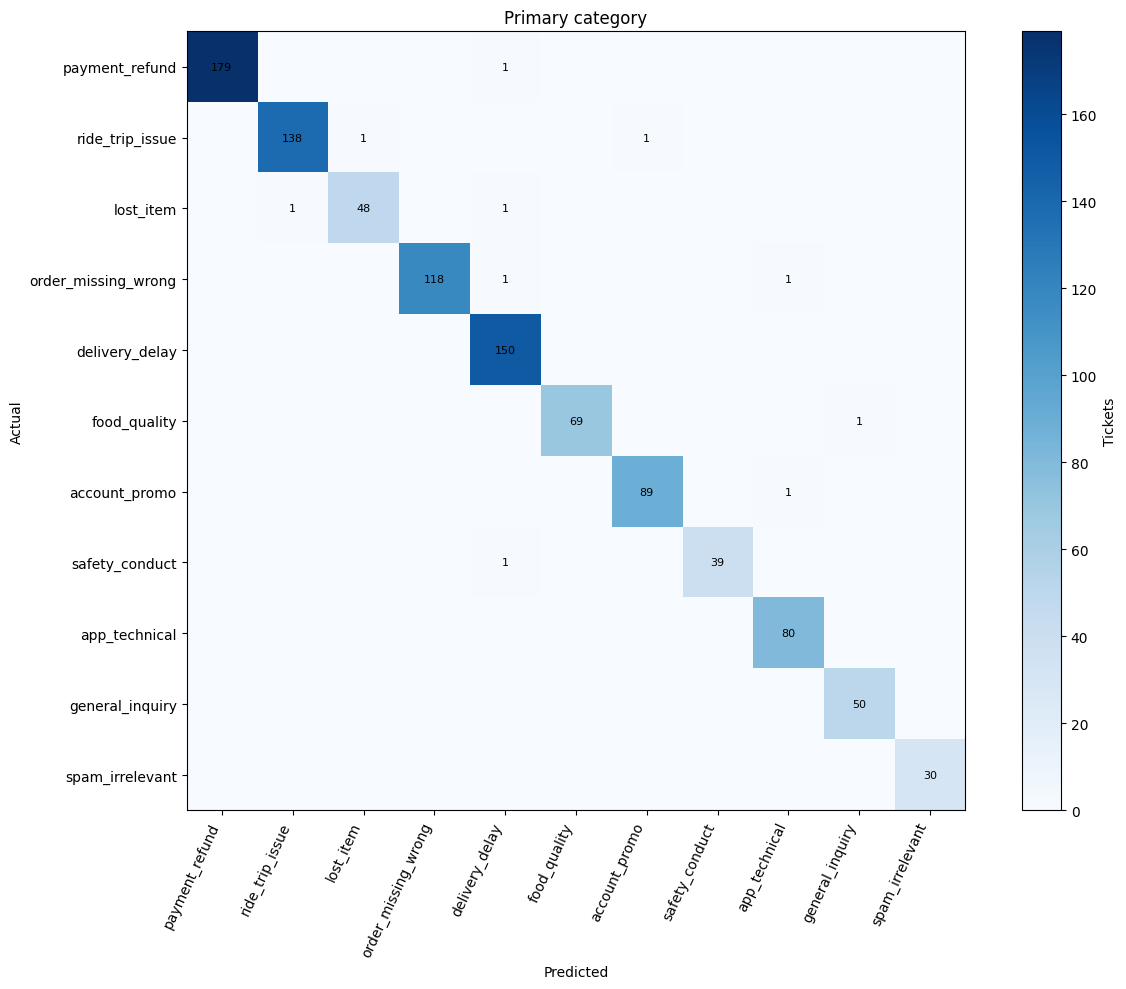

/var/folders/0r/kf0jwjkx3mjfb55r97hwcqq00000gn/T/ipykernel_44193/29992312.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


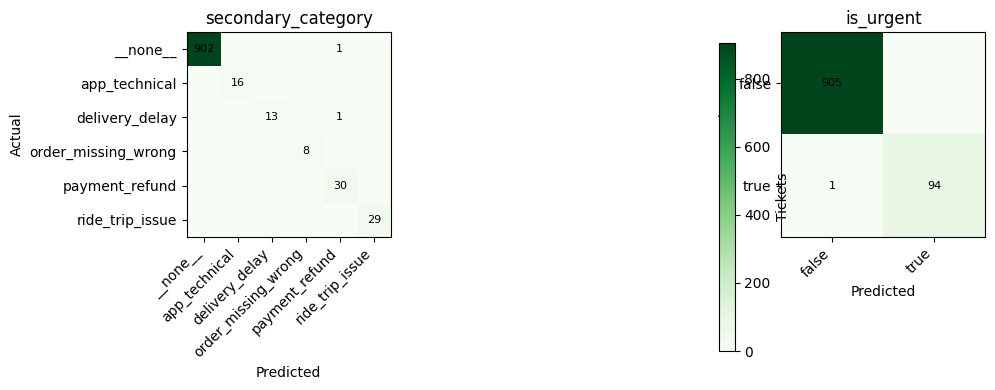

In [5]:
category_matrix = metrics["category_confusion_matrix"]
labels = category_matrix["labels"]
matrix = np.asarray(category_matrix["rows_actual_columns_predicted"])
fig, ax = plt.subplots(figsize=(13, 10))
image = ax.imshow(matrix, cmap="Blues")
ax.set(title="Primary category", xlabel="Predicted", ylabel="Actual", xticks=range(len(labels)), yticks=range(len(labels)))
ax.set_xticklabels(labels, rotation=65, ha="right")
ax.set_yticklabels(labels)
for row in range(len(labels)):
    for column in range(len(labels)):
        if matrix[row, column]:
            ax.text(column, row, str(matrix[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Tickets")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, target in zip(axes, ["secondary_category", "is_urgent"]):
    report = metrics["classification_reports"][target]
    class_labels = [name for name, value in report.items() if isinstance(value, dict) and name not in ("macro avg", "weighted avg")]
    cm = np.asarray(metrics["confusion_matrices"][target]["rows_actual_columns_predicted"])
    im = ax.imshow(cm, cmap="Greens")
    ax.set(title=target, xlabel="Predicted", ylabel="Actual", xticks=range(len(class_labels)), yticks=range(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=45, ha="right")
    ax.set_yticklabels(class_labels)
    for row in range(len(class_labels)):
        for column in range(len(class_labels)):
            if cm[row, column]:
                ax.text(column, row, str(cm[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Tickets")
fig.tight_layout()
plt.show()


## Performance by language

These are primary-category accuracy and macro-F1 grouped by the dataset language tag. Small groups (especially `mixed` and `tanglish`) have high uncertainty; do not interpret a perfect score on a small group as proof of parity.

,count,accuracy,macro_f1
en,356.0,0.9831,0.9825
mixed,23.0,1.0000,1.0000
si,198.0,1.0000,1.0000
singlish,255.0,0.9961,0.9978
ta,146.0,1.0000,1.0000
tanglish,22.0,0.8636,0.7778


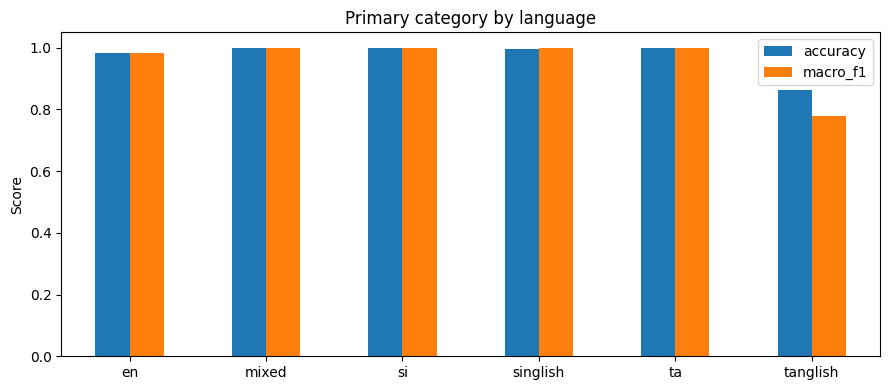

In [6]:
language_scores = pd.DataFrame(metrics["category_by_language"]).T.sort_index()
display(language_scores)
language_scores[["accuracy", "macro_f1"]].plot.bar(figsize=(9, 4), ylim=(0, 1.05), title="Primary category by language")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Delivery-delay vs. lost-property routing

A delayed, not-yet-arrived delivery belongs to `delivery_delay`; personal belongings left during a ride belong to `lost_item`. The table below isolates confusion counts from the measured 1,000-ticket test fold. The sample live predictions are a smoke check of the final full-data artifact, not part of the held-out score.

In [7]:
lost_index = labels.index("lost_item")
delay_index = labels.index("delivery_delay")
display(pd.DataFrame(
    [[matrix[lost_index, lost_index], matrix[lost_index, delay_index]],
     [matrix[delay_index, lost_index], matrix[delay_index, delay_index]]],
    index=["actual lost_item", "actual delivery_delay"],
    columns=["predicted lost_item", "predicted delivery_delay"],
))

from app.model import TicketModel
model = TicketModel.load(ROOT / "artifacts/model.joblib")
smoke_tickets = [
    {"channel": "chat", "text": "My food order is delayed and still has not arrived."},
    {"channel": "chat", "text": "I left my phone in the car after my ride."},
]
smoke_predictions = model.predict_many(smoke_tickets)
display(pd.DataFrame([
    {"message": ticket["text"], "category": prediction["category"], "team": prediction["team"], "confidence": prediction["confidence"]}
    for ticket, prediction in zip(smoke_tickets, smoke_predictions)
]))
assert smoke_predictions[0]["category"] == "delivery_delay"
assert smoke_predictions[1]["category"] == "lost_item"


,predicted lost_item,predicted delivery_delay
actual lost_item,48,1
actual delivery_delay,0,150


,message,category,team,confidence
0,My food order is delayed and still has not arr...,delivery_delay,Delivery Operations,0.997723
1,I left my phone in the car after my ride.,lost_item,Lost & Found,0.999815


## Release record and limitations

- **Release version:** `v2.1.0`; **model version:** `tf-phase2-drive-2.1.0`.
- **Training:** final deployable artifact trained on 4,800 labeled rows; model configurations and thresholds are frozen in `configs/training.json`.
- **Evaluation:** 3,000/1,000 stratified fit/test split from `train.csv`, random seed 42. The supplied `validation.csv` was excluded from test scoring and used only for the final refit.
- **Artifacts:** `artifacts/model.joblib`, `artifacts/evaluation_metrics.json`, and `artifacts/evaluation_breakdown.json`.
- **Reproduction:** run `python scripts/train_model.py`, then reopen this notebook and run all cells. Saved scores remain the original fold scores unless you deliberately retrain and replace them.

These data are synthetic, language subgroups are uneven, and high test scores can reflect repeated templates or other dataset-specific patterns. The supplied Sinhala/Tamil text has not been independently reviewed by native speakers. Validate on fresh, representative, human-reviewed examples before relying on this model for live customer routing. Human review remains important for ambiguous or low-confidence tickets.